# 8. Validación estadística del modelo original

La pregunta de este capítulo es si el modelo aditivo penalizado es **significativamente mejor** que los modelos de referencia. Para responderla no basta con una sola partición, porque la diferencia entre modelos buenos suele ser del orden de la variabilidad entre particiones. Por eso se repitió la validación cruzada anidada cinco veces con semillas distintas, lo que da 25 estimaciones pareadas (5 repeticiones por 5 pliegues externos) de cada modelo sobre exactamente las mismas particiones. La repetición 0 es la misma del capítulo 5.

Las pruebas siguen la lógica de Demšar (2006) para comparar varios modelos en varios conjuntos de datos, la corrección de Nadeau y Bengio (2003) para validación cruzada repetida, y DeLong y McNemar sobre la prueba externa. Todas las comparaciones del original contra los demás modelos se corrigen con el método de Holm.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display
warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RES, FIG = RAIZ / "resultados", RAIZ / "resultados" / "figuras"
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)

## 8.1 Hipótesis y criterio de decisión

Para cada modelo de referencia $M$:

$$H_0:\ \text{PR-AUC}(\text{original}) = \text{PR-AUC}(M) \qquad H_1:\ \text{PR-AUC}(\text{original}) > \text{PR-AUC}(M)$$

Se considera que el modelo original **supera** a los demás solo si se cumplen tres condiciones a la vez. La primera es que su media de PR-AUC sea la mayor. La segunda es que al menos tres pruebas distintas rechacen $H_0$ contra todos los modelos de referencia después del ajuste de Holm, con $\alpha = 0{,}05$. La tercera es que el tamaño del efecto no sea despreciable. Se fijó este criterio antes de mirar los resultados.

## 8.2 Rendimiento en la validación repetida

In [2]:
res = pd.read_csv(RES / "original_resumen.csv")
res.round(4)

,modelo,n_estimaciones,PR_AUC_media,PR_AUC_sd,IC95_BCa_inf,IC95_BCa_sup,ROC_AUC_media,Brier_media,ECE_media,t_entrenamiento_s,t_inferencia_s
0,EBM,25,0.5211,0.0124,0.5162,0.5255,0.7938,0.1305,0.0156,5.4529,0.0029
1,SVM,25,0.5202,0.0128,0.5153,0.5249,0.7936,0.1309,0.0215,0.5335,0.0553
2,AditivoPenalizado,25,0.5198,0.0133,0.5146,0.5246,0.7929,0.1307,0.0164,1.6059,0.0663
3,LogReg,25,0.5195,0.0135,0.5142,0.5243,0.7936,0.1307,0.0165,1.1669,0.0525
4,XGBoost,25,0.5176,0.0135,0.5125,0.5225,0.7911,0.1846,0.2247,0.6933,0.0597
5,RandomForest,25,0.5062,0.0122,0.5015,0.5107,0.7847,0.1346,0.0353,1.7674,0.1060
6,DecisionTree,25,0.4736,0.0124,0.4690,0.4785,0.7717,0.1360,0.0162,0.3225,0.0473
7,NaiveBayes,25,0.4712,0.0101,0.4675,0.4752,0.7531,0.2204,0.2052,0.5615,0.0540
8,KNN,25,0.4645,0.0134,0.4589,0.4690,0.7621,0.1430,0.0593,0.2217,7.9396


La tabla muestra media, desviación y el intervalo BCa del 95 % obtenido por remuestreo con corrección de sesgo y aceleración. Los intervalos de los mejores modelos se traslapan casi por completo, y eso anticipa el resultado de las pruebas.

## 8.3 Prueba de Friedman y diagrama de diferencia crítica

In [3]:
display(pd.read_csv(RES / "original_friedman.csv").round(4))
display(pd.read_csv(RES / "original_rangos.csv").round(3))

,universo,k_modelos,N_bloques,chi2,p,CD_nemenyi
0,"7 mejores + original, 25 bloques (5 rep x 5 pl...",8,25,146.0267,0.0,2.0998
1,7 mejores + EBM + original,9,25,162.9227,0.0,2.4026


,modelo,rango_medio
0,EBM,2.20
1,SVM,2.72
2,AditivoPenalizado,3.04
3,XGBoost,3.52
4,LogReg,3.68
5,RandomForest,5.84
6,DecisionTree,7.68
7,NaiveBayes,7.84
8,KNN,8.48


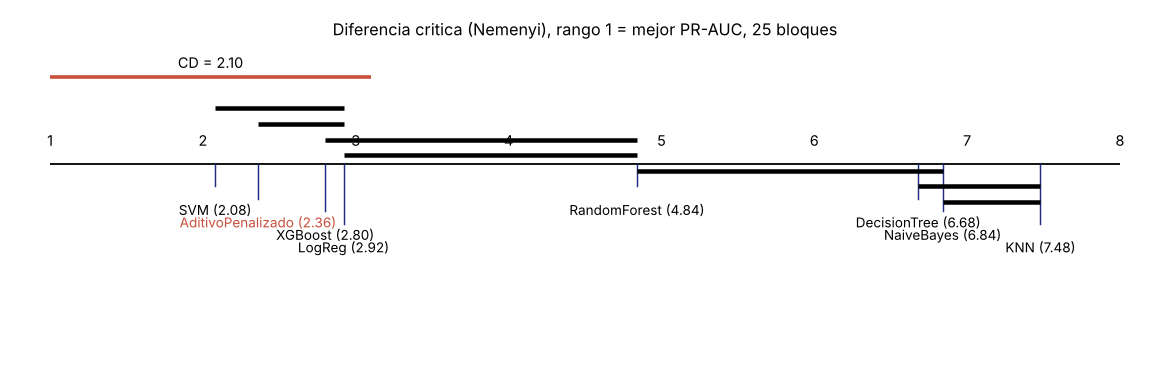

In [4]:
display(Image(filename=str(FIG / "original_cd.png")))

Friedman rechaza que todos los modelos sean equivalentes, y era de esperar, porque KNN, árbol de decisión y Bayes ingenuo son claramente peores. Lo que importa es la distancia entre el original y los primeros lugares, que se compara con la diferencia crítica de Nemenyi. Si dos modelos están unidos por una barra en el diagrama, no se pueden distinguir.

## 8.4 Comparaciones pareadas en la validación repetida

In [5]:
pp = pd.read_csv(RES / "original_pruebas_pareadas.csv")
cols = ["referencia", "dif_media_PR_AUC", "IC95_BCa_inf", "IC95_BCa_sup", "wilcoxon_p_holm", "nadeau_bengio_p_holm", "cliffs_delta", "cohen_dz"]
pp[cols].round(4)

,referencia,dif_media_PR_AUC,IC95_BCa_inf,IC95_BCa_sup,wilcoxon_p_holm,nadeau_bengio_p_holm,cliffs_delta,cohen_dz
0,KNN,0.0553,0.0525,0.0590,0.0000,0.0000,1.0000,6.5614
1,NaiveBayes,0.0487,0.0461,0.0508,0.0000,0.0000,0.9968,8.0591
2,DecisionTree,0.0462,0.0424,0.0502,0.0000,0.0000,0.9904,4.5730
3,RandomForest,0.0136,0.0112,0.0161,0.0000,0.0032,0.5200,2.1135
4,XGBoost,0.0023,0.0004,0.0054,0.4199,1.0000,0.1040,0.3659
5,LogReg,0.0003,-0.0002,0.0008,0.3598,1.0000,0.0144,0.2819
6,SVM,-0.0004,-0.0010,0.0003,0.4199,1.0000,-0.0016,-0.2088
7,EBM,-0.0013,-0.0022,-0.0006,0.0269,1.0000,-0.0528,-0.6070


Una diferencia positiva significa que el original es mejor. Wilcoxon no supone normalidad, y la t corregida de Nadeau y Bengio agranda la varianza para reconocer que las particiones comparten datos de entrenamiento. El delta de Cliff y la d de Cohen miden el tamaño del efecto, no la significancia.

## 8.5 Comparaciones en la prueba externa

In [6]:
pt = pd.read_csv(RES / "original_pruebas_prueba.csv")
pt.round(4)

,referencia,dif_AUC,delong_p,mcnemar_orig_acierta_ref_falla,mcnemar_orig_falla_ref_acierta,mcnemar_p,delong_p_holm,mcnemar_p_holm
0,LogReg,-0.0008,0.1377,76,87,0.4336,0.5509,0.4336
1,SVM,-0.0004,0.5781,125,177,0.0033,0.5781,0.0131
2,XGBoost,-0.0013,0.2421,202,167,0.0766,0.5509,0.1532
3,EBM,-0.0008,0.1537,134,95,0.0119,0.5509,0.0356


DeLong compara las áreas ROC de dos modelos evaluados sobre los mismos individuos. McNemar compara los aciertos con el umbral de 0,245 mirando solo los casos en que uno acierta y el otro falla.

## 8.6 Veredicto

In [7]:
v = json.load(open(RES / "original_veredicto.json"))
print("PR-AUC media del original: %.4f" % v["PR_AUC_media_original"])
for m, x in v["PR_AUC_media_por_referencia"].items():
    print("  %-14s %.4f   original gana en media: %s" % (m, x, v["el_original_gana_en_media_a"][m]))
print()
for k, x in v["pruebas_que_rechazan_a_favor_del_original"].items():
    print(("[x] " if x else "[ ] ") + k)
print()
print("Condición 1 (media mayor que todas):", v["condicion_1_media_mayor_que_todas"])
print("Condición 2 (al menos tres pruebas rechazan a su favor):", v["condicion_2_al_menos_tres_pruebas"])
print("Condición 3 (efecto no despreciable a su favor):", v["condicion_3_efecto_no_despreciable_a_favor"])
print("R3 cumplida:", v["R3_cumplida"], "| comparaciones totales corregidas:", v["comparaciones_totales"])

PR-AUC media del original: 0.5198
  DecisionTree   0.4736   original gana en media: True
  EBM            0.5211   original gana en media: False
  KNN            0.4645   original gana en media: True
  LogReg         0.5195   original gana en media: True
  NaiveBayes     0.4712   original gana en media: True
  RandomForest   0.5062   original gana en media: True
  SVM            0.5202   original gana en media: False
  XGBoost        0.5176   original gana en media: True

[ ] Friedman y Nemenyi (diferencia de rangos mayor que CD frente a todos)
[ ] Wilcoxon pareado con Holm
[ ] t corregida de Nadeau y Bengio con Holm
[ ] DeLong en la prueba con Holm
[ ] McNemar en la prueba con Holm

Condición 1 (media mayor que todas): False
Condición 2 (al menos tres pruebas rechazan a su favor): False
Condición 3 (efecto no despreciable a su favor): False
R3 cumplida: False | comparaciones totales corregidas: 25


**Lectura.** El modelo original supera de forma significativa a KNN, al árbol de decisión, a Bayes ingenuo y al bosque aleatorio, y queda empatado con la regresión logística y XGBoost (diferencias de milésimas, con valores p ajustados de 1). Con el SVM y el EBM la diferencia media es levemente desfavorable, y en la prueba externa McNemar con Holm detecta que esos dos modelos aciertan algo más que el original con el umbral de 0,245. Por eso no hay superioridad frente a todos los modelos y la condición R3 **no se cumple**. Es un resultado honesto y útil. Con 14 predictoras casi todas categóricas, la señal aditiva ya está casi toda capturada por la regresión logística, y las interacciones o no existen o aportan muy poco. Lo que sí ofrece el modelo original es calibración mejor que la mayoría (ECE bajo), curvas legibles por variable, SHAP exacto y un costo de entrenamiento bajo. Son ventajas de interpretabilidad y de transparencia, no de poder predictivo.

## 8.7 Limitaciones de esta validación

1. Las 25 estimaciones no son independientes, porque las repeticiones reutilizan los mismos individuos. Por eso se usa la corrección de Nadeau y Bengio, que es conservadora pero no perfecta.
2. La búsqueda de hiperparámetros dentro de cada pliegue usó un submuestreo de 8 000 filas y 12 evaluaciones, para que 8 modelos por 25 bloques fueran viables. Esto afecta por igual a todos los modelos, pero podría dejar a alguno algo por debajo de su óptimo.
3. Todos los modelos, incluido el EBM, completaron los 25 bloques, así que las comparaciones se hacen sobre el mismo universo.
4. No encontrar diferencia significativa no demuestra equivalencia. Solo indica que con estos datos y este tamaño de muestra no se puede distinguir.